# Proyecto 2, Clustering con Machine Learning y Aplicación Web
## Segmentación de clientes con *Customer Personality Analysis*

**Asignatura** Inteligencia Artificial, Ingeniería en Sistemas de Información (PUCE)
**Integrantes** Joselyn Cadena y Gabriel Aguinaga
**Dataset** [Customer Personality Analysis de Kaggle](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis), archivo `marketing_campaign.csv`

| Sección | Contenido |
|---|---|
| 1 | Contexto y pregunta de negocio |
| 2 | Análisis exploratorio (EDA) |
| 3 | Preparación de datos y escalado |
| 4 | Reducción de dimensionalidad con PCA |
| 5 | Modelado con K-Means y DBSCAN |
| 6 | Evaluación y comparación |
| 7 | Interpretación de los segmentos |
| 8 | Entrenamiento final y exportación |

## 1. Contexto y pregunta de negocio

Una cadena de supermercados que vende en tienda, por la web y por catálogo registró durante dos años los datos de
**2240 clientes**. Se conoce su ingreso, los hijos que tienen en casa, lo que gastaron en 6 categorías (vinos, frutas,
carnes, pescado, dulces y oro), cuántas compras hicieron por cada canal y si respondieron a las campañas.

**Pregunta de negocio.** *¿Qué grupos de clientes con hábitos de compra parecidos existen y cómo debería la empresa
adaptar sus campañas, canales y productos a cada uno?*

**Decisiones que permite tomar la segmentación**
- Elegir a qué clientes enviar campañas premium de vinos y carnes y a cuáles enviar promociones o descuentos.
- Elegir el canal más adecuado para cada grupo, ya sea tienda, web o catálogo.
- Asignar de forma automática a un **cliente nuevo** a su segmento por medio de la aplicación web.

No existe una variable objetivo, por lo que se trata de un problema **no supervisado**. Las columnas de respuesta a
campañas (`AcceptedCmp1` a `AcceptedCmp5` y `Response`) y la columna `Complain` son binarias, así que **no entran al
modelo** y solo se usan después para interpretar los perfiles.

In [1]:
#Librerías
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
RANDOM_STATE = 42          #semilla fija para que el notebook sea reproducible

## 2. Análisis exploratorio de datos (EDA)
### 2.1 Carga y estructura
El archivo original de Kaggle viene separado por **tabulaciones**. Se usa `sep=None` para que pandas detecte el
separador por su cuenta, así funciona tanto con tabulaciones como con punto y coma.

In [2]:
#Carga del dataset, el archivo marketing_campaign.csv está en la carpeta data de la raíz del proyecto
#Se busca esa raíz desde la carpeta actual para que el notebook funcione igual desde ml/notebooks o desde la raíz
#Los modelos se exportan en la carpeta models de la raíz
import os
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "marketing_campaign.csv").exists())
os.chdir(RAIZ)

df_raw = pd.read_csv("data/marketing_campaign.csv", sep=None, engine="python")
print("Dimensiones del dataset", df_raw.shape)
df_raw.head()

Dimensiones del dataset (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,5,0,0,0,0,0,0,3,11,0


In [3]:
#Tipos de variable y valores no nulos
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

**Tipos de variables**

| Tipo | Variables |
|---|---|
| Identificador | `ID` |
| Constantes sin información | `Z_CostContact`, `Z_Revenue` |
| Categóricas de texto | `Education`, `Marital_Status` |
| Fecha | `Dt_Customer` |
| Binarias de 0 y 1 | `AcceptedCmp1` a `AcceptedCmp5`, `Response`, `Complain` |
| Numéricas discretas o continuas | `Year_Birth`, `Income`, `Kidhome`, `Teenhome`, `Recency`, las variables de gasto `Mnt` y las de compras y visitas `Num` |

In [4]:
#Variables constantes que no aportan nada a la segmentación
print(df_raw[["Z_CostContact", "Z_Revenue"]].nunique())

#Valores faltantes por columna
faltantes = df_raw.isna().sum()
print("\nValores faltantes por columna\n", faltantes[faltantes > 0])
print(f"Porcentaje de Income faltante {df_raw['Income'].isna().mean()*100:.2f}%")

Z_CostContact    1
Z_Revenue        1
dtype: int64

Valores faltantes por columna
 Income    24
dtype: int64
Porcentaje de Income faltante 1.07%


In [5]:
#Estadísticos descriptivos de las variables numéricas
df_raw.describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.2,3246.7,0.0,2828.2,5458.5,8427.8,11191.0
Year_Birth,2240.0,1968.8,12.0,1893.0,1959.0,1970.0,1977.0,1996.0
Income,2216.0,52247.3,25173.1,1730.0,35303.0,51381.5,68522.0,666666.0
Kidhome,2240.0,0.4,0.5,0.0,0.0,0.0,1.0,2.0
Teenhome,2240.0,0.5,0.5,0.0,0.0,0.0,1.0,2.0
Recency,2240.0,49.1,29.0,0.0,24.0,49.0,74.0,99.0
MntWines,2240.0,303.9,336.6,0.0,23.8,173.5,504.2,1493.0
MntFruits,2240.0,26.3,39.8,0.0,1.0,8.0,33.0,199.0
MntMeatProducts,2240.0,167.0,225.7,0.0,16.0,67.0,232.0,1725.0
MntFishProducts,2240.0,37.5,54.6,0.0,3.0,12.0,50.0,259.0


**Observaciones iniciales**
- `Income` tiene **24 valores faltantes, que son el 1.07 %**, y un máximo de **666666**, lo cual es un error de captura.
- `Year_Birth` tiene valores entre 1893 y 1900, es decir, clientes de más de 110 años, que también son errores.
- Las variables de gasto tienen medias muy por debajo de sus máximos, lo que indica **distribuciones sesgadas a la derecha**.

### 2.2 Variables derivadas para el análisis
- `Age` se calcula como 2014 menos `Year_Birth`. El último registro de `Dt_Customer` es de 2014, por eso la edad se
  calcula a esa fecha. Con el año actual todos los clientes tendrían unos 12 años más de los que tenían al comprar.
- `Children` es la suma de `Kidhome` y `Teenhome`, es decir, el total de hijos en casa, con valores de 0 a 3.
- `TotalSpent`, que suma los 6 gastos, y `TotalPurchases` se usan **solo para interpretar**. No entran al modelo
  porque son combinaciones exactas de variables que ya están en X.

In [6]:
df = df_raw.copy()
df["Dt_Customer"] = pd.to_datetime(df["Dt_Customer"], format="mixed", dayfirst=True)
print("Rango de fechas de alta entre", df["Dt_Customer"].min().date(), "y", df["Dt_Customer"].max().date())

ANIO_REF = 2014
df["Age"] = ANIO_REF - df["Year_Birth"]
df["Children"] = df["Kidhome"] + df["Teenhome"]

MNT = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
NUM_COMPRAS = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
df["TotalSpent"] = df[MNT].sum(axis=1)
df["TotalPurchases"] = df[NUM_COMPRAS].sum(axis=1)
df[["Age", "Children", "TotalSpent", "TotalPurchases"]].describe().round(1)

Rango de fechas de alta entre 2012-01-08 y 2014-12-06


,Age,Children,TotalSpent,TotalPurchases
count,2240.0,2240.0,2240.0,2240.0
mean,45.2,1.0,605.8,12.5
std,12.0,0.8,602.2,7.2
min,18.0,0.0,5.0,0.0
25%,37.0,0.0,68.8,6.0
50%,44.0,1.0,396.0,12.0
75%,55.0,1.0,1045.5,18.0
max,121.0,3.0,2525.0,32.0


### 2.3 Visualización 1, distribución de las variables numéricas

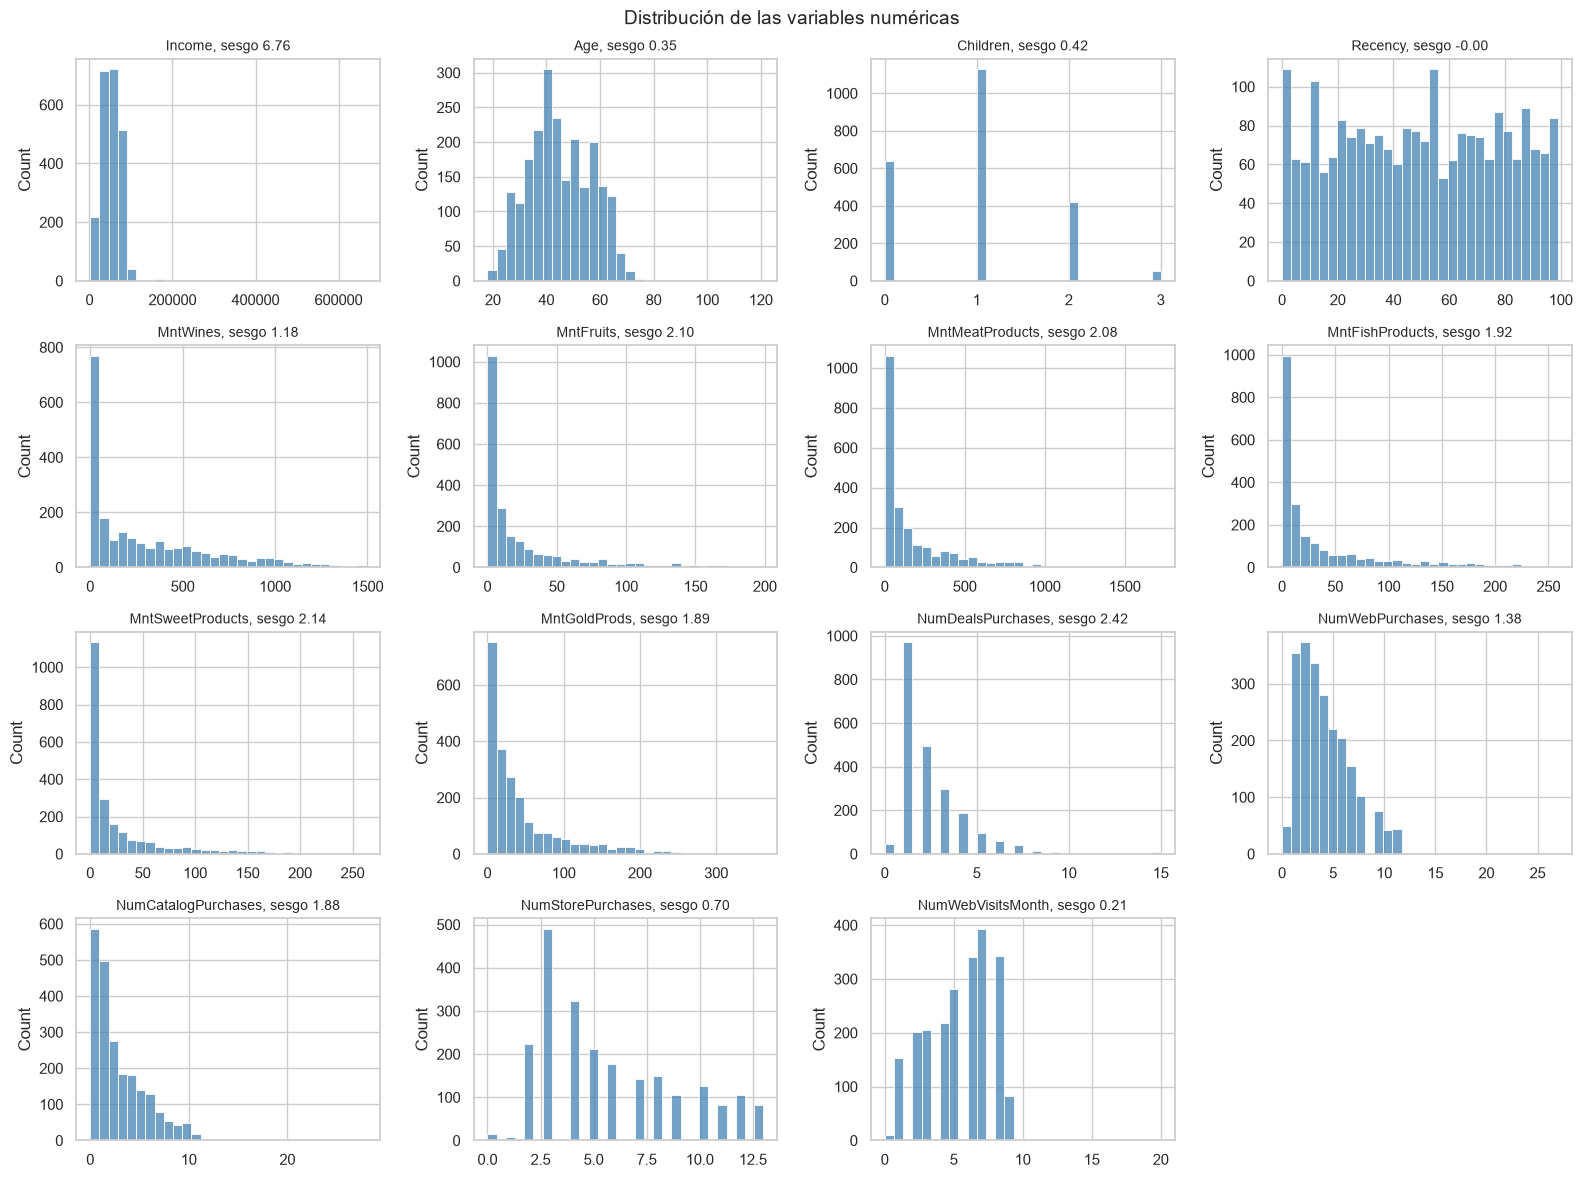

In [7]:
VARS_EDA = ["Income", "Age", "Children", "Recency"] + MNT + \
           ["NumDealsPurchases"] + NUM_COMPRAS + ["NumWebVisitsMonth"]

fig, axes = plt.subplots(4, 4, figsize=(16, 12))
for ax, col in zip(axes.flat, VARS_EDA):
    sns.histplot(df[col].dropna(), bins=30, ax=ax, color="steelblue")
    ax.set_title(f"{col}, sesgo {df[col].skew():.2f}", fontsize=10)
    ax.set_xlabel("")
axes.flat[-1].axis("off")
plt.suptitle("Distribución de las variables numéricas", fontsize=14)
plt.tight_layout(); plt.show()

Las variables de gasto y las compras por catálogo están **muy sesgadas a la derecha**, ya que la mayoría de clientes
gasta poco y una minoría gasta mucho. `Recency` es casi uniforme entre 0 y 99 días, por lo que se espera que aporte
poco a la separación de los grupos.

### 2.4 Visualización 2, valores atípicos con diagramas de caja

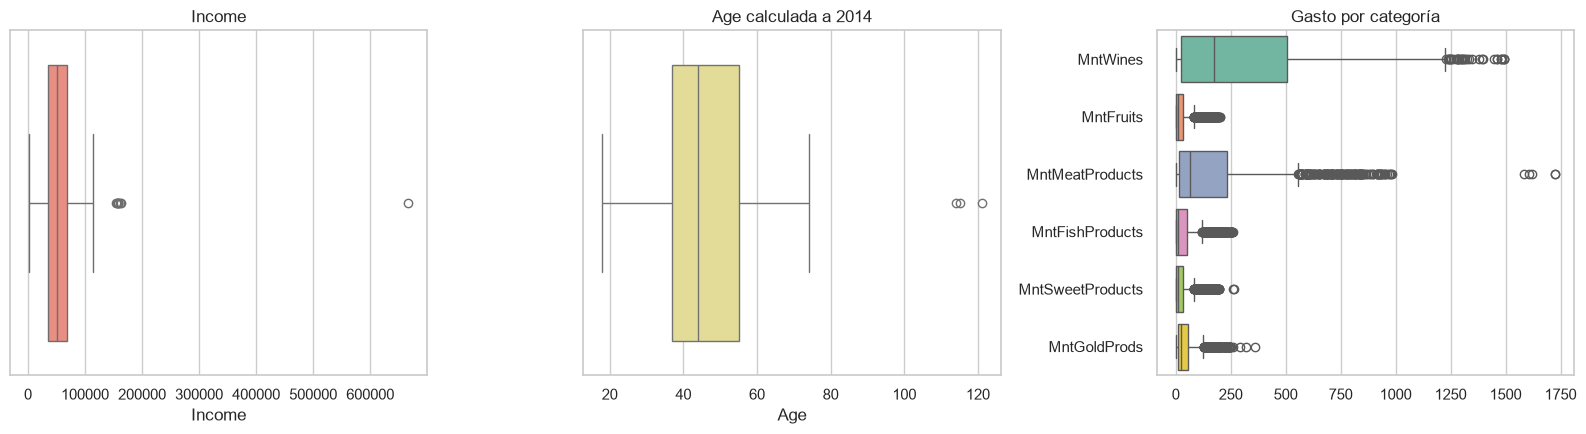

Clientes con Income mayor a 200000
         ID    Income  TotalSpent
2233  9432  666666.0          62

Clientes con Age mayor a 100
         ID  Year_Birth  Age
192   7829        1900  114
239  11004        1893  121
339   1150        1899  115


In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x=df["Income"], ax=axes[0], color="salmon");   axes[0].set_title("Income")
sns.boxplot(x=df["Age"], ax=axes[1], color="khaki");       axes[1].set_title("Age calculada a 2014")
sns.boxplot(data=df[MNT], orient="h", ax=axes[2], palette="Set2"); axes[2].set_title("Gasto por categoría")
plt.tight_layout(); plt.show()

print("Clientes con Income mayor a 200000\n", df.loc[df["Income"] > 200_000, ["ID", "Income", "TotalSpent"]])
print("\nClientes con Age mayor a 100\n", df.loc[df["Age"] > 100, ["ID", "Year_Birth", "Age"]])

**Efecto de los atípicos en K-Means.** K-Means minimiza las distancias euclidianas al cuadrado, por eso un solo punto
extremo, como un ingreso de 666666, **arrastra un centroide** hacia él o incluso forma un cluster propio. Además
aumenta la desviación estándar que usa `StandardScaler` y deja al resto de clientes muy juntos.

- Los **errores evidentes**, como edades mayores a 100 años o el ingreso de 666666, se eliminan. Son 4 registros, es
  decir, el 0.18 %.
- Los **gastos altos no se eliminan**, porque son clientes reales de alto valor y justamente se busca encontrarlos
  como un segmento.

### 2.5 Visualización 3, matriz de correlación

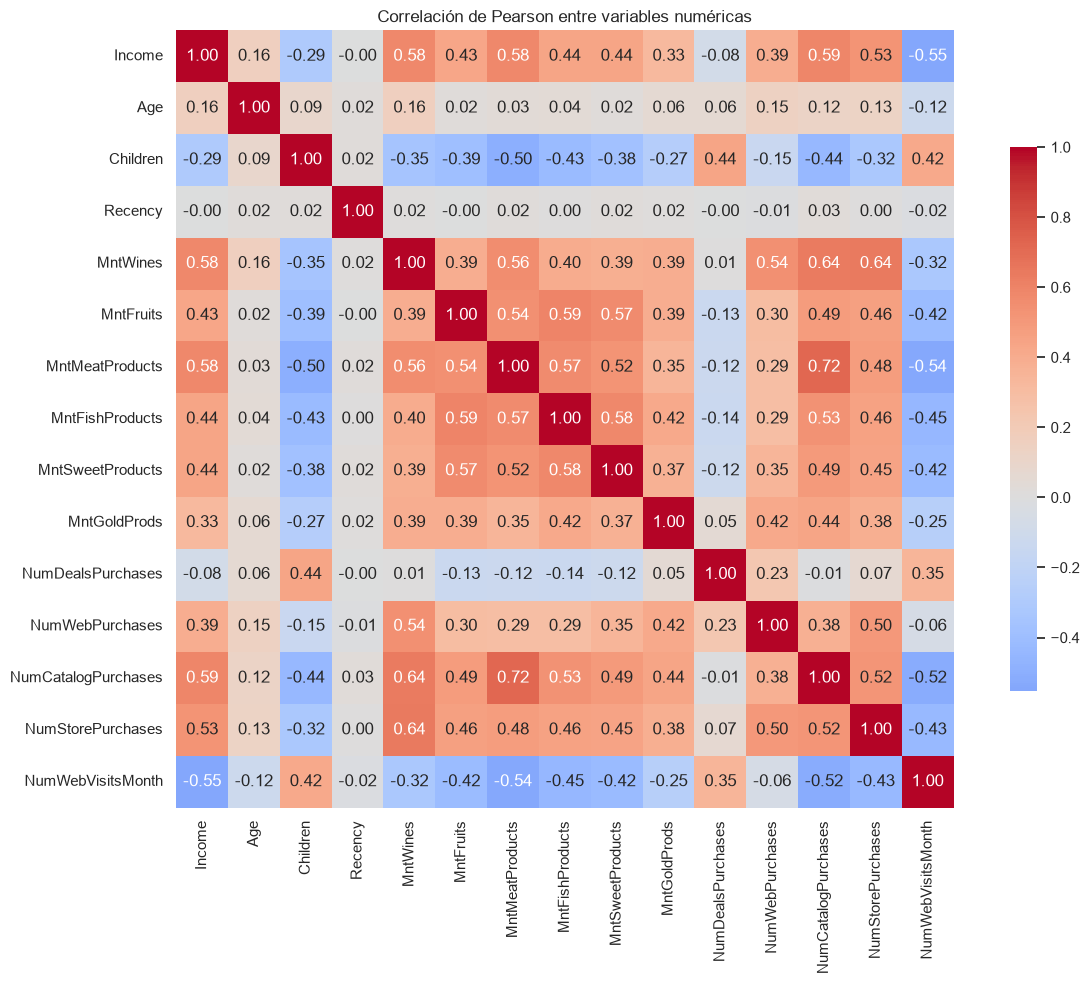

In [9]:
plt.figure(figsize=(13, 10))
corr = df[VARS_EDA].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": .7})
plt.title("Correlación de Pearson entre variables numéricas")
plt.tight_layout(); plt.show()

- `Income`, todas las variables de gasto, `NumCatalogPurchases` y `NumStorePurchases` están **muy correlacionadas**
  entre sí, con valores entre 0.5 y 0.7. Todas describen un mismo eje de poder adquisitivo y nivel de gasto.
- `Children` y `NumWebVisitsMonth` tienen una correlación **negativa** con el gasto, ya que los hogares con hijos
  visitan más la web pero compran menos.
- Esta redundancia justifica el uso de **PCA**, porque varias variables comparten la misma información.

### 2.6 Visualización 4, gasto frente a ingreso según el número de hijos

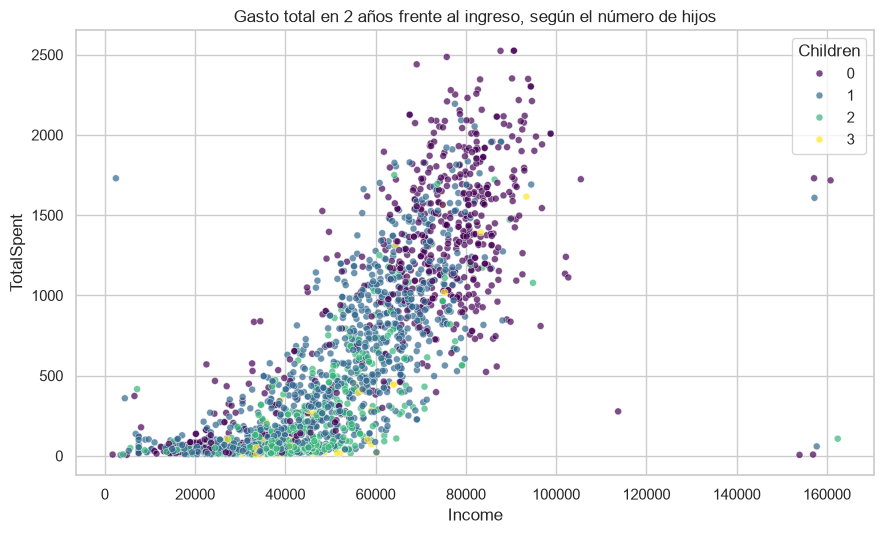

In [10]:
plt.figure(figsize=(9, 5.5))
sns.scatterplot(data=df[df["Income"] < 200_000], x="Income", y="TotalSpent",
                hue="Children", palette="viridis", alpha=.7, s=25)
plt.title("Gasto total en 2 años frente al ingreso, según el número de hijos")
plt.tight_layout(); plt.show()

En el gráfico ya se notan algunos grupos, como clientes de ingreso bajo con gasto mínimo y clientes de ingreso alto sin hijos con gasto alto.

## 3. Preparación de datos

| Decisión | Justificación |
|---|---|
| Eliminar los registros con `Age` mayor a 100 e `Income` mayor a 200000, que son 4 filas | Son errores de captura que mueven los centroides y afectan el escalado |
| Completar `Income` faltante con la **mediana** | Solo falta el 1 % y la mediana no se ve afectada por el sesgo de la distribución |
| Excluir `ID`, `Z_CostContact` y `Z_Revenue` | Son un identificador y dos constantes sin información |
| Excluir `Education` y `Marital_Status` | Son categóricas de texto, como pide el proyecto |
| Excluir `AcceptedCmp`, `Response` y `Complain` | Son binarias y se reservan para interpretar los perfiles |
| Excluir `Dt_Customer` | Es una fecha y no describe el comportamiento de compra |
| Usar `Children` en lugar de `Kidhome` y `Teenhome` | Resume ambas en una variable de 0 a 3 y reduce la redundancia |
| Usar `Age` en lugar de `Year_Birth` | Es más fácil de interpretar y tiene la misma información |
| Aplicar `StandardScaler` | Las variables tienen escalas muy distintas, el ingreso está en decenas de miles y las compras en unidades. Sin escalar, el ingreso dominaría la distancia euclidiana |

In [11]:
#3.1 Limpieza de errores
n0 = len(df)
df = df[(df["Age"] <= 100) & ~(df["Income"] > 200_000)].copy()
print(f"Filas eliminadas por errores {n0 - len(df)}, quedan {len(df)}")

#3.2 Income faltante completado con la mediana
mediana_income = df["Income"].median()
df["Income"] = df["Income"].fillna(mediana_income)
print(f"Income completado con la mediana {mediana_income:,.0f}, faltantes restantes {df['Income'].isna().sum()}")
df = df.reset_index(drop=True)

Filas eliminadas por errores 4, quedan 2236
Income completado con la mediana 51,371, faltantes restantes 0


In [12]:
#3.3 Selección de las variables numéricas no binarias que entran al clustering
FEATURES = [
    "Income", "Age", "Children", "Recency",
    "MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds",
    "NumDealsPurchases", "NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth",
]
BINARIAS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "Response", "Complain"]

X = df[FEATURES]
print("Variables en X", len(FEATURES))
print("Valores únicos por variable, todas tienen más de 2 y por eso no son binarias")
print(X.nunique().to_string())

Variables en X 15
Valores únicos por variable, todas tienen más de 2 y por eso no son binarias
Income                 1971
Age                      56
Children                  4
Recency                 100
MntWines                775
MntFruits               158
MntMeatProducts         557
MntFishProducts         182
MntSweetProducts        177
MntGoldProds            213
NumDealsPurchases        15
NumWebPurchases          15
NumCatalogPurchases      14
NumStorePurchases        14
NumWebVisitsMonth        16


In [13]:
#3.4 Escalado con StandardScaler, con media 0 y desviación 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pd.DataFrame(X_scaled, columns=FEATURES).describe().loc[["mean", "std"]].round(2)

,Income,Age,Children,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
mean,0.0,0.0,0.0,-0.0,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,0.0,-0.0,-0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


## 4. Reducción de dimensionalidad con PCA
### 4.1 Varianza explicada

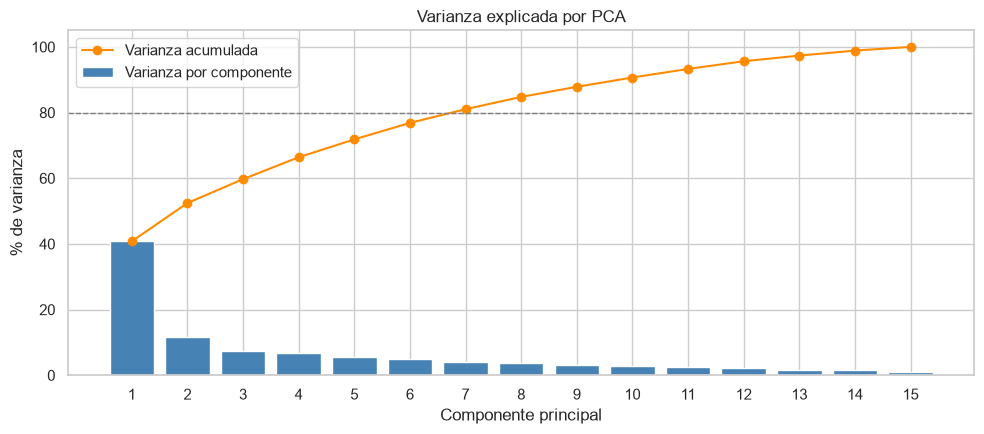

,Varianza %,Acumulada %
PC1,40.79,40.79
PC2,11.66,52.45
PC3,7.28,59.73
PC4,6.66,66.39
PC5,5.45,71.83
PC6,5.01,76.85
PC7,4.18,81.03
PC8,3.74,84.77


In [14]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
var = pca_full.explained_variance_ratio_
var_acum = np.cumsum(var)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.bar(range(1, len(var) + 1), var * 100, color="steelblue", label="Varianza por componente")
ax.plot(range(1, len(var) + 1), var_acum * 100, "o-", color="darkorange", label="Varianza acumulada")
ax.axhline(80, ls="--", color="gray", lw=1)
ax.set_xlabel("Componente principal"); ax.set_ylabel("% de varianza"); ax.set_xticks(range(1, len(var) + 1))
ax.legend(); ax.set_title("Varianza explicada por PCA")
plt.tight_layout(); plt.show()

pd.DataFrame({"Varianza %": (var * 100).round(2), "Acumulada %": (var_acum * 100).round(2)},
             index=[f"PC{i}" for i in range(1, len(var) + 1)]).head(8)

PC1 explica por sí sola cerca del **41 %** de la varianza y junto con PC2 llega a cerca del **52 %**. Desde PC3 cada
componente aporta menos del 8 %, así que el codo de la varianza está en PC2.

### 4.2 Cargas de cada componente

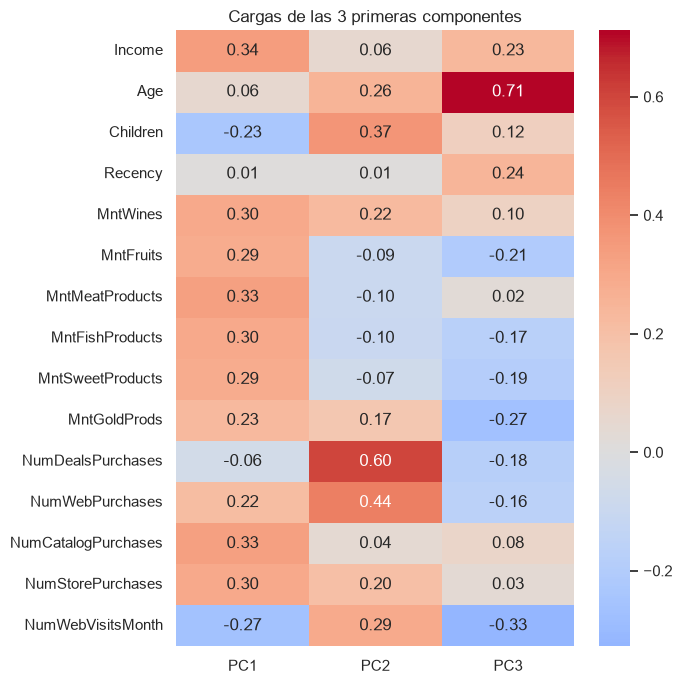

In [15]:
loadings = pd.DataFrame(pca_full.components_[:3].T, index=FEATURES, columns=["PC1", "PC2", "PC3"])
plt.figure(figsize=(7, 7))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Cargas de las 3 primeras componentes")
plt.tight_layout(); plt.show()

**Interpretación**
- **PC1 representa el poder adquisitivo y el nivel de gasto.** Tiene cargas positivas altas en `Income`, en todas las
  variables de gasto, en `NumCatalogPurchases` y en `NumStorePurchases`, y cargas negativas en `Children` y
  `NumWebVisitsMonth`. Un valor alto de PC1 corresponde a un cliente de ingreso y gasto altos, sin hijos.
- **PC2 representa a las familias que buscan ofertas y compran por internet.** Tiene cargas altas en
  `NumDealsPurchases` (0.60), `NumWebPurchases`, `Children`, `NumWebVisitsMonth` y `Age`. Un valor alto de PC2
  corresponde a un cliente con hijos que compra con descuentos y por la web.
- `Recency` tiene una carga cercana a 0 en ambas componentes, lo que confirma que casi no aporta a la estructura de
  los datos.

### 4.3 Decisión de entrenar los modelos sobre PC1 y PC2

Se decide entrenar **K-Means y DBSCAN sobre las 2 primeras componentes principales** y no sobre las 15 variables.
1. **Las dos componentes tienen un significado claro para el negocio**, que es el nivel de gasto y la búsqueda de
   ofertas en familias. Esto hace que los segmentos sean fáciles de interpretar.
2. **Con muchas dimensiones las distancias pierden capacidad para diferenciar puntos.** En la sección 5.3 se comprobó
   que con las 15 variables escaladas el Silhouette de K-Means baja a 0.33 con K igual a 2 y a 0.21 con K igual a 4,
   mientras que en el espacio PCA sube a 0.55 y 0.47.
3. **DBSCAN depende de la densidad**, que en muchas dimensiones es casi uniforme. En 2D el k dist graph se puede leer
   con claridad.
4. **El mapa 2D de la aplicación es el mismo espacio donde se asigna el cluster**, así que lo que el usuario ve es lo
   mismo que usa el modelo para decidir.

*Costo asumido.* Se deja de lado cerca del 48 % de la varianza, que corresponde sobre todo a diferencias individuales
en `Recency`, `Age` y entre categorías de gasto que no forman grupos.

Varianza retenida con 2 componentes 52.45%


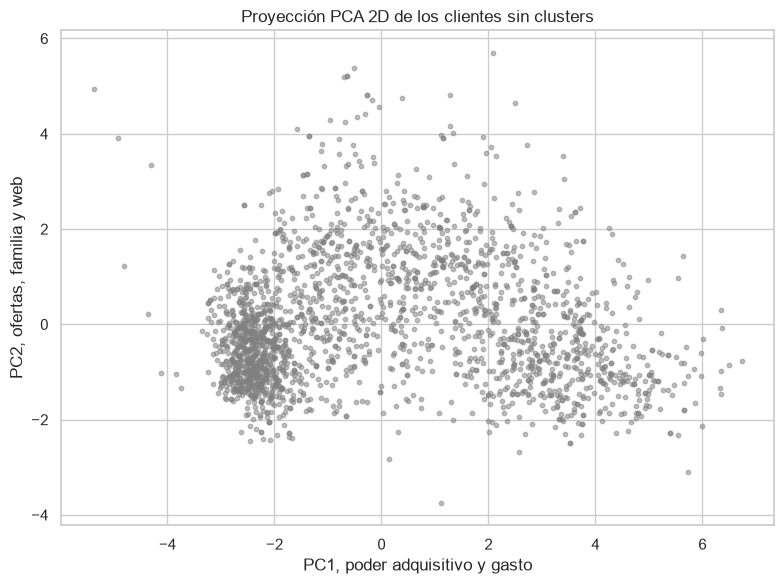

In [16]:
N_COMP = 2
pca = PCA(n_components=N_COMP, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f"Varianza retenida con {N_COMP} componentes {pca.explained_variance_ratio_.sum()*100:.2f}%")

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], s=10, alpha=.5, c="gray")
plt.xlabel("PC1, poder adquisitivo y gasto"); plt.ylabel("PC2, ofertas, familia y web")
plt.title("Proyección PCA 2D de los clientes sin clusters")
plt.tight_layout(); plt.show()

## 5. Modelado
### 5.1 Elección de K en K-Means con el codo y el Silhouette, para K entre 2 y 9
Cada modelo se arma dentro de un `Pipeline` con `StandardScaler`, `PCA` y `KMeans`, para asegurar que el mismo
preprocesamiento se aplique en el entrenamiento y en la aplicación.

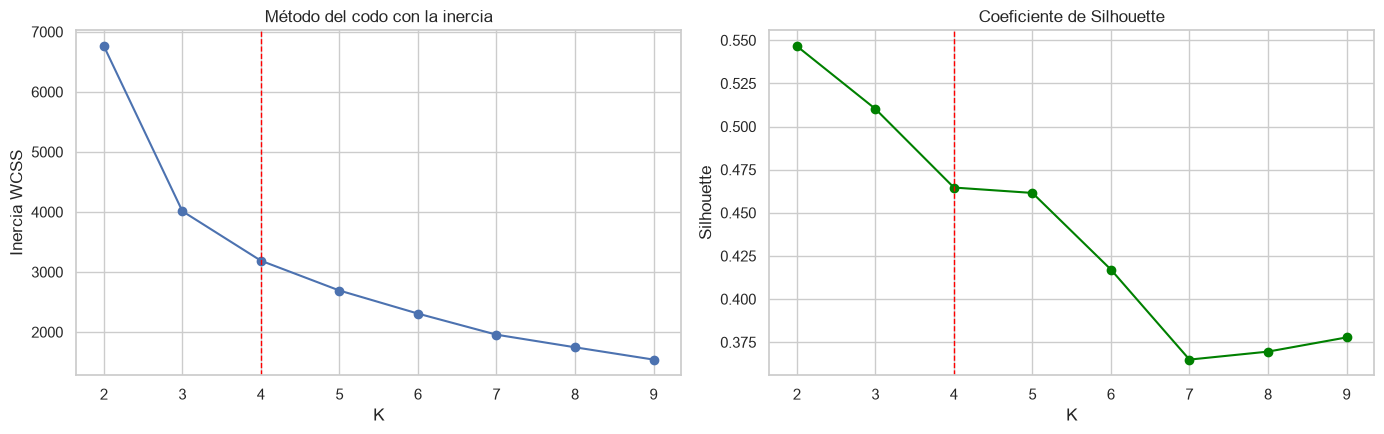

,Inercia,Silhouette
K,,
2,6762.195,0.547
3,4012.919,0.510
4,3188.463,0.465
5,2691.943,0.462
6,2307.643,0.417
7,1956.412,0.365
8,1746.492,0.370
9,1541.484,0.378


In [17]:
resultados_k = []
for k in range(2, 10):
    pipe_k = Pipeline([
        ("scaler", StandardScaler()),
        ("pca", PCA(n_components=N_COMP, random_state=RANDOM_STATE)),
        ("kmeans", KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)),
    ])
    etiquetas = pipe_k.fit_predict(X)
    Xp = pipe_k[:-1].transform(X)                       #espacio PCA donde se agrupa
    resultados_k.append({
        "K": k,
        "Inercia": pipe_k["kmeans"].inertia_,
        "Silhouette": silhouette_score(Xp, etiquetas),
    })
res_k = pd.DataFrame(resultados_k).set_index("K")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(res_k.index, res_k["Inercia"], "o-"); axes[0].set_title("Método del codo con la inercia")
axes[0].set_xlabel("K"); axes[0].set_ylabel("Inercia WCSS")
axes[1].plot(res_k.index, res_k["Silhouette"], "o-", color="green"); axes[1].set_title("Coeficiente de Silhouette")
axes[1].set_xlabel("K"); axes[1].set_ylabel("Silhouette")
for ax in axes: ax.axvline(4, ls="--", color="red", lw=1)
plt.tight_layout(); plt.show()
res_k.round(3)

**Se elige K igual a 4.**
- **Codo.** La inercia baja mucho entre K igual a 2 y K igual a 4, y desde K igual a 4 la mejora es pequeña porque la
  curva se aplana.
- **Silhouette.** K igual a 2 tiene el valor más alto, cerca de 0.55, pero solo separa a quienes gastan mucho de
  quienes gastan poco, lo cual es muy básico para marketing. K igual a 4 mantiene un Silhouette cercano a **0.47**, que
  indica una estructura razonable, y es el último valor antes de que baje de 0.42 desde K igual a 6.
- **Utilidad para el negocio.** Con K igual a 4 los clientes de gasto medio se dividen en dos perfiles diferentes, los
  consolidados y las familias que buscan ofertas, que con K igual a 2 o 3 quedan mezclados.

In [18]:
K_OPT = 4
pipe_kmeans = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=N_COMP, random_state=RANDOM_STATE)),
    ("kmeans", KMeans(n_clusters=K_OPT, n_init=10, random_state=RANDOM_STATE)),
])
labels_km = pipe_kmeans.fit_predict(X)
Xp = pipe_kmeans[:-1].transform(X)                      #coordenadas PCA, iguales para ambos modelos

sil_km = silhouette_score(Xp, labels_km)
print(f"K-Means con K={K_OPT}, Silhouette {sil_km:.3f} e inercia {pipe_kmeans['kmeans'].inertia_:.1f}")
print("Tamaño de cada cluster", np.bincount(labels_km))

K-Means con K=4, Silhouette 0.465 e inercia 3188.5
Tamaño de cada cluster [989 474 434 339]


### 5.2 DBSCAN, `min_samples` con la regla práctica y `eps` con el k dist graph
- **min_samples.** La regla vista en clase indica que MinPts debe ser al menos D más 1 y se sugiere usar 2 por D. Como
  DBSCAN se entrena en el mismo espacio PCA de **D igual a 2** dimensiones, `min_samples` queda en 4.
- **eps.** Se ordenan de menor a mayor las distancias de cada punto a su vecino número k, con k igual a min_samples,
  y se busca el codo de la curva. Para ubicarlo de forma objetiva se usa el punto más alejado de la recta que une el
  primer y el último valor, conocido como método *kneedle*.

D es 2 por lo que min_samples es 4


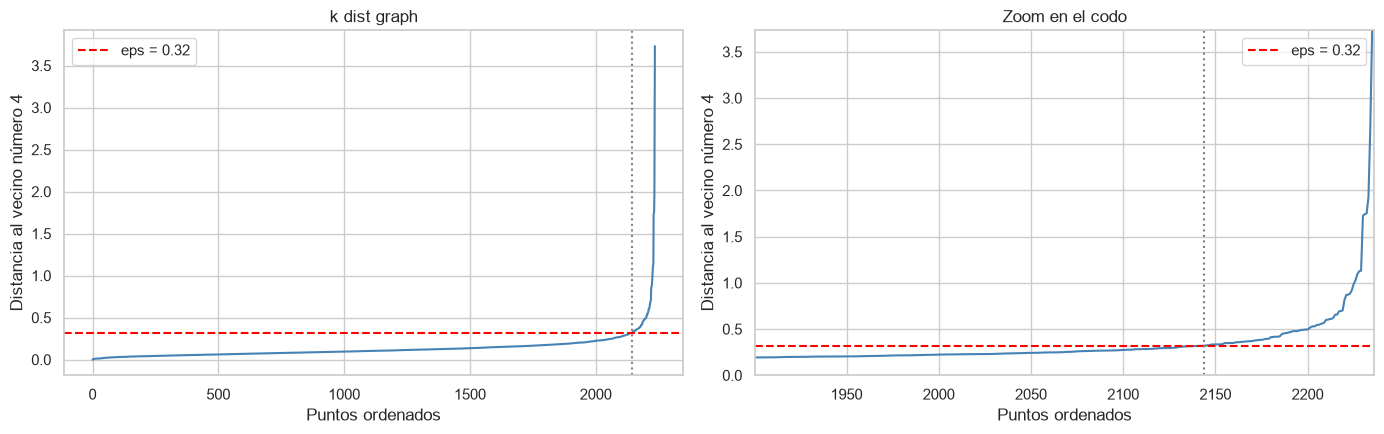

Codo en el punto 2144 de 2236, percentil 95.9, por lo que eps es 0.32


In [19]:
D = N_COMP
MIN_SAMPLES = 2 * D
print("D es", D, "por lo que min_samples es", MIN_SAMPLES)

#k dist graph con la distancia al vecino número k, n_neighbors incluye al propio punto igual que DBSCAN
nn = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(Xp)
k_dist = np.sort(nn.kneighbors(Xp)[0][:, -1])

#El codo es el punto más alejado de la recta que une los extremos de la curva
idx = np.arange(len(k_dist))
p1, p2 = np.array([0, k_dist[0]]), np.array([idx[-1], k_dist[-1]])
v, w = p2 - p1, np.c_[idx, k_dist] - p1
dist_recta = np.abs(v[0] * w[:, 1] - v[1] * w[:, 0]) / np.linalg.norm(v)   #producto cruz en 2D
codo = int(np.argmax(dist_recta))
EPS = float(round(k_dist[codo], 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, zoom in zip(axes, [False, True]):
    ax.plot(k_dist, color="steelblue")
    ax.axhline(EPS, ls="--", color="red", label=f"eps = {EPS}")
    ax.axvline(codo, ls=":", color="gray")
    ax.set_xlabel("Puntos ordenados"); ax.set_ylabel(f"Distancia al vecino número {MIN_SAMPLES}")
    if zoom: ax.set_xlim(len(k_dist) * .85, len(k_dist)); ax.set_ylim(0, k_dist.max()); ax.set_title("Zoom en el codo")
    else: ax.set_title("k dist graph")
    ax.legend()
plt.tight_layout(); plt.show()
print(f"Codo en el punto {codo} de {len(k_dist)}, percentil {codo/len(k_dist)*100:.1f}, por lo que eps es {EPS}")

In [20]:
def resumen_dbscan(etiquetas, Xp):
    #Número de clusters, porcentaje de ruido y Silhouette calculado sin los puntos de ruido
    mask = etiquetas != -1
    n_cl = len(set(etiquetas[mask]))
    sil = silhouette_score(Xp[mask], etiquetas[mask]) if n_cl > 1 else np.nan
    return n_cl, (~mask).mean() * 100, sil

pipe_dbscan = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=N_COMP, random_state=RANDOM_STATE)),
    ("dbscan", DBSCAN(eps=EPS, min_samples=MIN_SAMPLES)),
])
labels_db = pipe_dbscan.fit_predict(X)
n_cl_db, ruido_db, sil_db = resumen_dbscan(labels_db, Xp)

print(f"DBSCAN con eps={EPS} y min_samples={MIN_SAMPLES}")
print(f"  Clusters encontrados {n_cl_db}")
print(f"  Ruido {ruido_db:.2f}%")
print(f"  Silhouette sin ruido {sil_db:.3f}")
print("  Tamaños", pd.Series(labels_db).value_counts().sort_index().to_dict())

DBSCAN con eps=0.32 y min_samples=4
  Clusters encontrados 10
  Ruido 2.64%
  Silhouette sin ruido -0.225
  Tamaños {-1: 59, 0: 2125, 1: 5, 2: 4, 3: 10, 4: 5, 5: 4, 6: 9, 7: 7, 8: 4, 9: 4}


### 5.3 Análisis de sensibilidad de DBSCAN
Para comprobar que el resultado no depende de una mala elección de `eps`, se prueban varios valores cercanos al codo
y también valores más altos de `min_samples`.

In [21]:
filas = []
for ms in [4, 6, 10]:
    kd = np.sort(NearestNeighbors(n_neighbors=ms).fit(Xp).kneighbors(Xp)[0][:, -1])
    for q in [0.85, 0.90, 0.95, 0.98]:
        e = kd[int(q * (len(kd) - 1))]
        et = DBSCAN(eps=e, min_samples=ms).fit_predict(Xp)
        n, r, s = resumen_dbscan(et, Xp)
        tam = pd.Series(et[et != -1]).value_counts()
        filas.append({"min_samples": ms, "percentil eps": q, "eps": round(e, 3), "clusters": n,
                      "% ruido": round(r, 2), "Silhouette": round(s, 3),
                      "% en cluster mayor": round(tam.max() / len(et) * 100, 1)})
pd.DataFrame(filas)

,min_samples,percentil eps,eps,clusters,% ruido,Silhouette,% en cluster mayor
0,4,0.85,0.192,30,9.08,-0.503,82.1
1,4,0.90,0.227,16,6.26,-0.428,90.3
2,4,0.95,0.295,13,3.22,-0.254,94.0
3,4,0.98,0.466,4,1.39,0.225,98.0
4,6,0.85,0.243,7,9.88,-0.397,88.2
5,6,0.90,0.286,4,6.22,-0.315,92.8
6,6,0.95,0.402,3,2.77,0.147,96.7
7,6,0.98,0.600,2,0.98,0.257,98.7
8,10,0.85,0.317,1,9.08,NaN,90.9
9,10,0.90,0.390,1,5.95,NaN,94.1


In [22]:
#Referencia de lo que pasaría sin PCA, con las 15 variables escaladas, para justificar la sección 4.3
sil_15 = {k: silhouette_score(X_scaled, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_scaled))
          for k in [2, 3, 4]}
print("Silhouette de K-Means con las 15 variables escaladas", {k: round(v, 3) for k, v in sil_15.items()})

ms15 = 2 * len(FEATURES)       #regla de 2 por D con D igual a 15
kd15 = np.sort(NearestNeighbors(n_neighbors=ms15).fit(X_scaled).kneighbors(X_scaled)[0][:, -1])
for q in [0.85, 0.95]:
    et = DBSCAN(eps=kd15[int(q * (len(kd15) - 1))], min_samples=ms15).fit_predict(X_scaled)
    print(f"DBSCAN en 15D con min_samples={ms15} y eps en el percentil {int(q*100)}, clusters={len(set(et) - {-1})}, "
          f"ruido={np.mean(et == -1)*100:.1f}%")

Silhouette de K-Means con las 15 variables escaladas {2: 0.328, 3: 0.234, 4: 0.206}


DBSCAN en 15D con min_samples=30 y eps en el percentil 85, clusters=1, ruido=2.3%


DBSCAN en 15D con min_samples=30 y eps en el percentil 95, clusters=1, ruido=1.0%


**Conclusión sobre DBSCAN.** En todas las combinaciones probadas, incluso sin PCA, DBSCAN encuentra **un solo cluster
denso que reúne entre el 82 % y el 99 % de los clientes**, junto con algunos grupos muy pequeños de 4 a 10 puntos en
los bordes y un porcentaje de ruido. El Silhouette sin ruido es bajo o **negativo**, porque esos grupos pequeños quedan
pegados al bloque principal.

Esto se debe a la forma de los datos. Los clientes forman un **continuo con una densidad parecida**, desde el gasto
bajo hasta el gasto alto, sin zonas vacías que separen grupos. DBSCAN solo separa regiones divididas por zonas de baja
densidad, por eso considera a casi todos los clientes como un mismo grupo. En cambio, sí resulta útil para
**detectar clientes atípicos**, que quedan como ruido.

## 6. Evaluación y comparación de modelos

In [23]:
comparacion = pd.DataFrame({
    "K-Means": {
        "Hiperparámetros": f"K={K_OPT}",
        "N° clusters": K_OPT,
        "Silhouette": round(sil_km, 3),
        "% ruido": 0.0,
        "Tamaños": str(np.bincount(labels_km).tolist()),
        "Cluster mayor (%)": round(np.bincount(labels_km).max() / len(labels_km) * 100, 1),
    },
    "DBSCAN": {
        "Hiperparámetros": f"eps={EPS}, min_samples={MIN_SAMPLES}",
        "N° clusters": n_cl_db,
        "Silhouette": round(sil_db, 3),
        "% ruido": round(ruido_db, 2),
        "Tamaños": str(pd.Series(labels_db[labels_db != -1]).value_counts().sort_index().tolist()),
        "Cluster mayor (%)": round(pd.Series(labels_db).value_counts().drop(-1, errors="ignore").max()
                                   / len(labels_db) * 100, 1),
    },
})
comparacion

,K-Means,DBSCAN
Hiperparámetros,K=4,"eps=0.32, min_samples=4"
N° clusters,4,10
Silhouette,0.465,-0.225
% ruido,0.0,2.64
Tamaños,"[989, 474, 434, 339]","[2125, 5, 4, 10, 5, 4, 9, 7, 4, 4]"
Cluster mayor (%),44.2,95.0


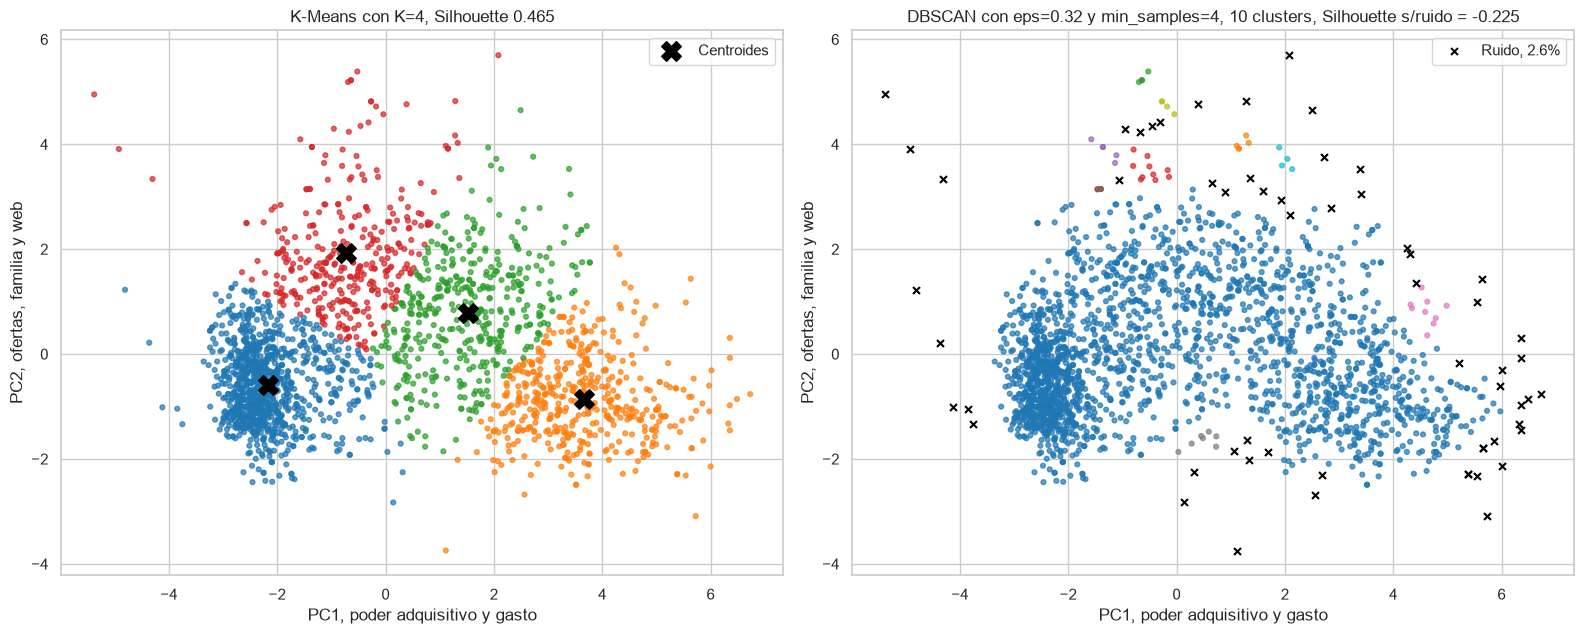

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

#K-Means
sc = axes[0].scatter(Xp[:, 0], Xp[:, 1], c=labels_km, cmap="tab10", s=12, alpha=.7, vmin=0, vmax=9)
cent = pipe_kmeans["kmeans"].cluster_centers_
axes[0].scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=200, label="Centroides")
axes[0].set_title(f"K-Means con K={K_OPT}, Silhouette {sil_km:.3f}")
axes[0].legend()

#DBSCAN
ruido = labels_db == -1
axes[1].scatter(Xp[~ruido, 0], Xp[~ruido, 1], c=labels_db[~ruido], cmap="tab10", s=12, alpha=.7)
axes[1].scatter(Xp[ruido, 0], Xp[ruido, 1], c="black", marker="x", s=25, label=f"Ruido, {ruido_db:.1f}%")
axes[1].set_title(f"DBSCAN con eps={EPS} y min_samples={MIN_SAMPLES}, {n_cl_db} clusters, "
                  f"Silhouette s/ruido = {sil_db:.3f}")
axes[1].legend()

for ax in axes:
    ax.set_xlabel("PC1, poder adquisitivo y gasto"); ax.set_ylabel("PC2, ofertas, familia y web")
plt.tight_layout(); plt.show()

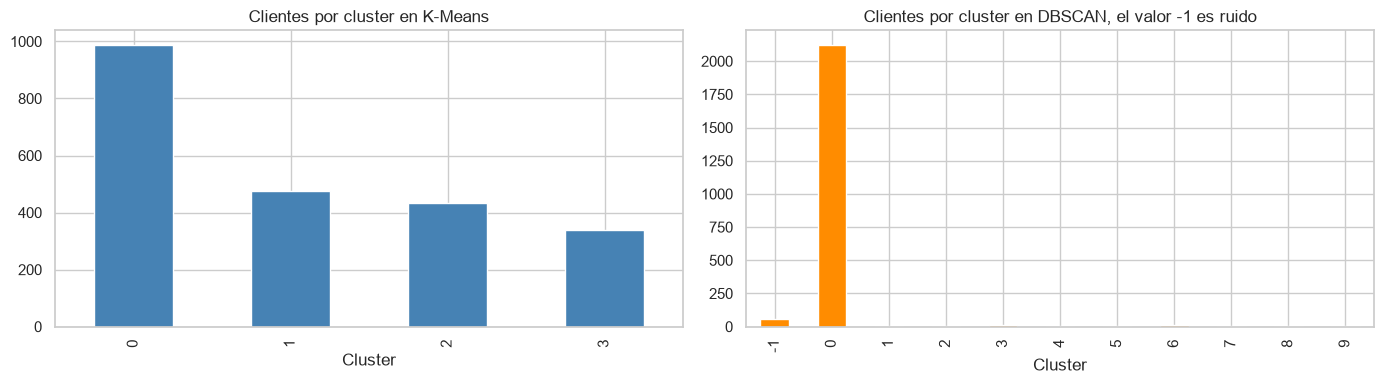

In [25]:
#Tamaño de cada cluster en ambos modelos
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pd.Series(labels_km).value_counts().sort_index().plot.bar(ax=axes[0], color="steelblue")
axes[0].set_title("Clientes por cluster en K-Means"); axes[0].set_xlabel("Cluster")
pd.Series(labels_db).value_counts().sort_index().plot.bar(ax=axes[1], color="darkorange")
axes[1].set_title("Clientes por cluster en DBSCAN, el valor -1 es ruido"); axes[1].set_xlabel("Cluster")
plt.tight_layout(); plt.show()

### 6.1 Modelo que produce una segmentación más útil

| Criterio | K-Means | DBSCAN |
|---|---|---|
| Silhouette | **Cerca de 0.47**, estructura razonable | Bajo o negativo, con grupos pequeños que se cruzan |
| Tamaño de los grupos | 4 grupos equilibrados, entre 15 % y 44 % | Un cluster con casi todos los clientes y varios grupos muy pequeños |
| Ruido | 0 %, todos los clientes quedan asignados | Un pequeño porcentaje de clientes queda sin segmento |
| Utilidad para marketing | 4 perfiles distintos y útiles | Casi todos los clientes quedan iguales, no permite diferenciar campañas |
| Datos nuevos | Usa `predict()` | Usa la regla del core más cercano |

**Modelo final elegido, K-Means con K igual a 4.** Los datos no tienen regiones separadas por baja densidad, que es lo
que DBSCAN necesita. K-Means, en cambio, divide el continuo de clientes en grupos compactos alrededor de centroides
que sí tienen sentido para el negocio. DBSCAN se mantiene como modelo de apoyo para **marcar clientes atípicos**, y la
aplicación lo muestra como información adicional.

## 7. Interpretación de los segmentos con el modelo final K-Means
### 7.1 Perfil promedio en escala original con `groupby().mean()`
En las variables binarias el promedio es la **proporción** de clientes del cluster que aceptaron la campaña.

In [26]:
df["Cluster"] = labels_km
perfil = df.groupby("Cluster")[FEATURES + ["TotalSpent", "TotalPurchases"]].mean()
perfil_bin = df.groupby("Cluster")[BINARIAS].mean()
perfil["N clientes"] = df["Cluster"].value_counts().sort_index()
perfil["% clientes"] = (perfil["N clientes"] / len(df) * 100).round(1)
perfil.T.round(1)

Cluster,0,1,2,3
Income,34867.1,77738.4,63878.9,50474.3
Age,42.4,44.8,48.7,48.9
Children,1.2,0.1,0.8,1.5
Recency,49.1,49.8,49.1,48.3
MntWines,37.6,602.7,551.0,348.0
MntFruits,4.7,71.6,39.3,9.1
MntMeatProducts,20.8,495.7,204.2,86.2
MntFishProducts,6.9,106.3,50.8,13.7
MntSweetProducts,4.8,74.8,39.0,9.9
MntGoldProds,14.5,78.1,69.3,50.0


In [27]:
#Proporción de clientes que aceptaron cada campaña, por cluster
perfil_bin.T.round(3)

Cluster,0,1,2,3
AcceptedCmp1,0.001,0.224,0.060,0.032
AcceptedCmp2,0.002,0.021,0.032,0.012
AcceptedCmp3,0.068,0.076,0.078,0.077
AcceptedCmp4,0.012,0.108,0.124,0.147
AcceptedCmp5,0.000,0.270,0.076,0.003
Response,0.082,0.281,0.143,0.171
Complain,0.011,0.004,0.012,0.006


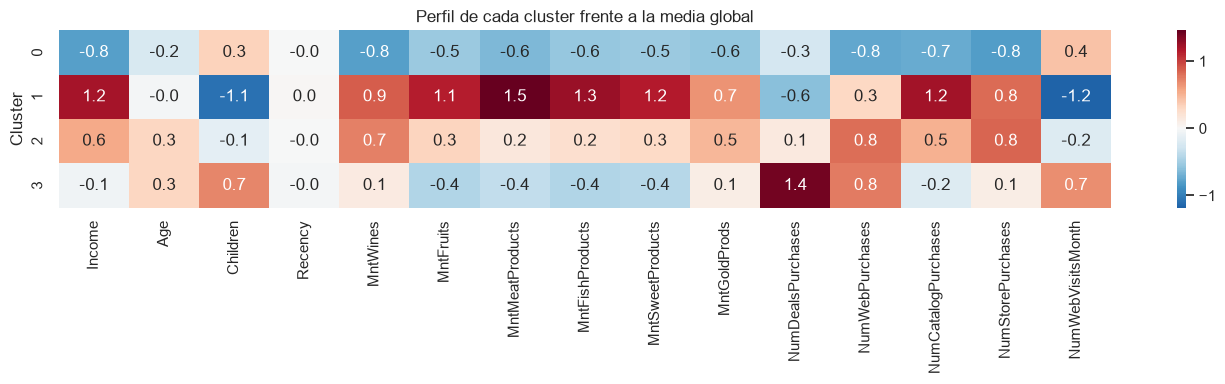

In [28]:
#Perfiles con valores estandarizados para comparar variables de escalas distintas
z = (perfil[FEATURES] - df[FEATURES].mean()) / df[FEATURES].std()
plt.figure(figsize=(14, 4))
sns.heatmap(z, annot=True, fmt=".1f", cmap="RdBu_r", center=0)
plt.title("Perfil de cada cluster frente a la media global")
plt.tight_layout(); plt.show()

### 7.2 Nombres de los segmentos
El número que K-Means asigna a cada cluster no sigue ningún orden, por eso los nombres se asignan **con reglas sobre
el perfil** y no a mano. Así el notebook sigue siendo correcto si se vuelve a ejecutar.
- El cluster con **menor gasto total** se llama *Ahorradores de bajo ingreso*.
- El cluster con **mayor gasto total** se llama *Premium de alto gasto*.
- De los dos restantes, el que tiene **más compras con descuento** se llama *Familias cazadoras de ofertas* y el otro
  se llama *Consolidados multicanal*.

In [29]:
orden_gasto = perfil["TotalSpent"].sort_values()
bajo, alto = orden_gasto.index[0], orden_gasto.index[-1]
medios = list(orden_gasto.index[1:-1])
ofertas = perfil.loc[medios, "NumDealsPurchases"].idxmax()
consolidado = [c for c in medios if c != ofertas][0]

SEGMENTOS = {
    int(bajo): {
        "nombre": "Ahorradores de bajo ingreso",
        "descripcion": "Clientes de ingreso bajo, con hijos y con un gasto mínimo en todas las categorías. "
                       "Visitan mucho la web, pero compran poco.",
        "recomendacion": "Campañas de canasta básica y marca propia, junto con cupones digitales de bajo costo "
                         "en la web para convertir las visitas en compras.",
    },
    int(alto): {
        "nombre": "Premium de alto gasto",
        "descripcion": "Clientes de ingreso alto, casi sin hijos y con el mayor gasto en vinos y carnes. Compran "
                       "mucho por catálogo y en tienda, casi no usan descuentos y son los que más responden a las campañas.",
        "recomendacion": "Programa VIP con catálogo de vinos, carnes y pescado, preventas exclusivas y "
                         "atención personalizada, sin ofrecer descuentos.",
    },
    int(ofertas): {
        "nombre": "Familias cazadoras de ofertas",
        "descripcion": "Clientes de ingreso medio, con la mayor cantidad de hijos y el mayor uso de compras con "
                       "descuento. Compran por la web y visitan mucho el sitio.",
        "recomendacion": "Promociones 2x1 y paquetes familiares por correo y web, con descuentos en productos de "
                         "consumo frecuente para subir el valor de cada compra.",
    },
    int(consolidado): {
        "nombre": "Consolidados multicanal",
        "descripcion": "Clientes de ingreso medio alto, con menos de un hijo en promedio y un gasto alto en vinos "
                       "y oro. Compran por todos los canales, es decir, web, tienda y catálogo.",
        "recomendacion": "Venta cruzada de vino con productos gourmet y beneficios por comprar en varios canales. "
                         "Son candidatos a pasar al grupo Premium con una membresía.",
    },
}
df["Segmento"] = df["Cluster"].map(lambda c: SEGMENTOS[c]["nombre"])
resumen = perfil[["Income", "Age", "Children", "TotalSpent", "NumDealsPurchases", "NumWebVisitsMonth", "% clientes"]].copy()
resumen.insert(0, "Segmento", [SEGMENTOS[c]["nombre"] for c in resumen.index])
resumen["Tasa Response"] = perfil_bin["Response"]
resumen.round(2)

,Segmento,Income,Age,Children,TotalSpent,NumDealsPurchases,NumWebVisitsMonth,% clientes,Tasa Response
Cluster,,,,,,,,,
0,Ahorradores de bajo ingreso,34867.11,42.38,1.20,89.37,1.84,6.34,44.2,0.08
1,Premium de alto gasto,77738.42,44.78,0.14,1429.21,1.15,2.45,21.2,0.28
2,Consolidados multicanal,63878.88,48.70,0.85,953.70,2.60,4.83,19.4,0.14
3,Familias cazadoras de ofertas,50474.26,48.87,1.48,516.96,5.03,6.98,15.2,0.17


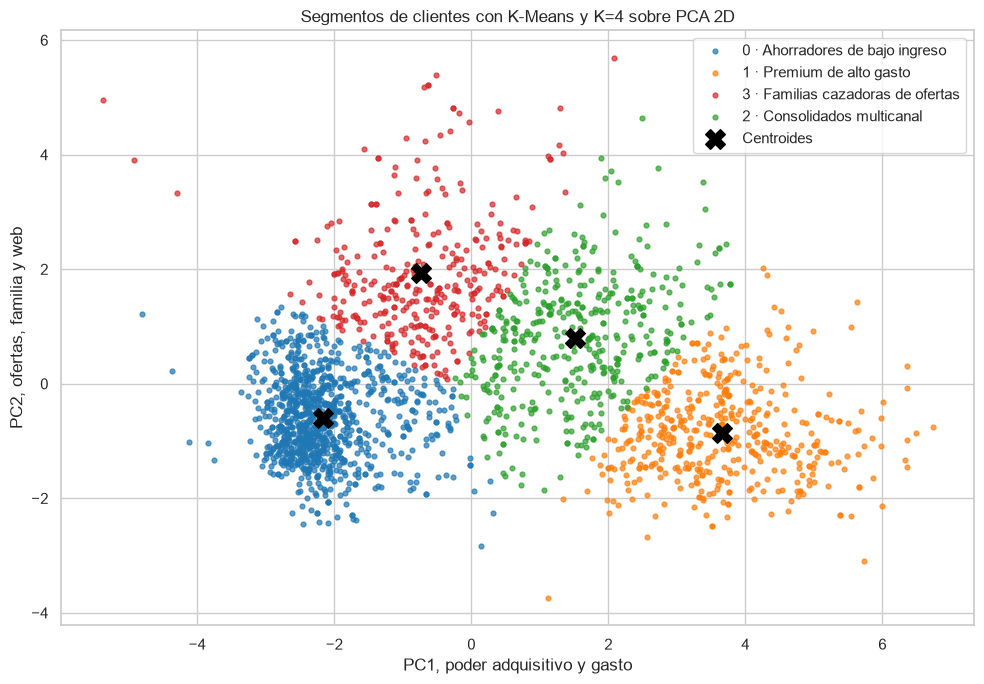

In [30]:
#Mapa PCA final con los nombres de los segmentos
plt.figure(figsize=(10, 7))
for c, info in SEGMENTOS.items():
    m = labels_km == c
    plt.scatter(Xp[m, 0], Xp[m, 1], s=12, alpha=.7, label=f"{c} · {info['nombre']}", color=plt.cm.tab10(c))
plt.scatter(cent[:, 0], cent[:, 1], c="black", marker="X", s=200, label="Centroides")
plt.xlabel("PC1, poder adquisitivo y gasto"); plt.ylabel("PC2, ofertas, familia y web")
plt.title("Segmentos de clientes con K-Means y K=4 sobre PCA 2D")
plt.legend(); plt.tight_layout(); plt.show()

### 7.3 Lectura de negocio

| Cluster | Segmento | Perfil | Acción recomendada |
|---|---|---|---|
| 0 | **Ahorradores de bajo ingreso** | Cerca del 44 % de los clientes, ingreso de unos 35000, 1.2 hijos en promedio y un gasto de unos 90 en 2 años | Canasta básica, marca propia y cupones digitales |
| 1 | **Premium de alto gasto** | Cerca del 21 %, ingreso de unos 78000, casi sin hijos, gasto de unos 1430 y la mejor respuesta a campañas, cerca del 30 % | Programa VIP y catálogo premium, sin descuentos |
| 2 | **Consolidados multicanal** | Cerca del 19 %, ingreso de unos 64000, mayor edad, gasto de unos 950 en vino y oro y compras por todos los canales | Venta cruzada y una membresía para pasar a Premium |
| 3 | **Familias cazadoras de ofertas** | Cerca del 15 %, ingreso de unos 50000, 1.5 hijos en promedio y el mayor uso de descuentos y visitas web | Promociones 2x1 y paquetes familiares por internet |

*La numeración de los clusters se obtuvo con `random_state=42` y los valores son promedios aproximados.*

## 8. Entrenamiento final y exportación
En clustering no existe una división entre entrenamiento y prueba, por eso el modelo final se entrena con el **100 % de
los datos**, como ya se hizo en `pipe_kmeans`. Se exporta con `joblib`.

| Archivo | Contenido |
|---|---|
| `models/kmeans_model.pkl` | **Modelo final**, el pipeline con `StandardScaler`, PCA de 2 componentes y KMeans de 4 grupos, junto con los nombres, descripciones, recomendaciones, perfiles y métricas |
| `models/dbscan_model.pkl` | Modelo de comparación, el pipeline con `StandardScaler`, PCA y DBSCAN, junto con `NearestNeighbors` sobre los puntos core para asignar datos nuevos |
| `models/datos_pca.csv` | Coordenadas PCA y cluster de cada cliente para el gráfico 2D de la aplicación |

In [31]:
import os
os.makedirs("models", exist_ok=True)

#Rangos de cada variable que la aplicación usa para validar y configurar el formulario
rangos = {c: {"min": float(df[c].min()), "max": float(df[c].max()), "mediana": float(df[c].median())}
          for c in FEATURES}

paquete_kmeans = {
    "pipeline": pipe_kmeans,
    "features": FEATURES,
    "segmentos": SEGMENTOS,
    "perfiles": perfil[FEATURES + ["TotalSpent", "% clientes"]].round(2),
    "perfiles_binarias": perfil_bin.round(3),
    "rangos": rangos,
    "metricas": {"K": K_OPT, "silhouette": float(sil_km), "inercia": float(pipe_kmeans["kmeans"].inertia_),
                 "varianza_pca": float(pipe_kmeans["pca"].explained_variance_ratio_.sum())},
}
joblib.dump(paquete_kmeans, "models/kmeans_model.pkl")

#En DBSCAN los datos nuevos se asignan con el punto core más cercano, guardado en components_
db = pipe_dbscan["dbscan"]
nn_core = NearestNeighbors(n_neighbors=1).fit(db.components_)
paquete_dbscan = {
    "pipeline": pipe_dbscan,
    "features": FEATURES,
    "nn_core": nn_core,
    "core_labels": db.labels_[db.core_sample_indices_],
    "eps": EPS,
    "min_samples": MIN_SAMPLES,
    "metricas": {"clusters": int(n_cl_db), "ruido_pct": float(ruido_db), "silhouette_sin_ruido": float(sil_db)},
}
joblib.dump(paquete_dbscan, "models/dbscan_model.pkl")

#Datos para el gráfico de la aplicación
pd.DataFrame({"PC1": Xp[:, 0], "PC2": Xp[:, 1], "Cluster_KMeans": labels_km, "Cluster_DBSCAN": labels_db,
              "Segmento": df["Segmento"]}).to_csv("models/datos_pca.csv", index=False)
print("Archivos exportados", sorted(os.listdir("models")))

Archivos exportados ['datos_pca.csv', 'dbscan_model.pkl', 'kmeans_model.pkl']


### 8.1 Verificación, carga de los `.pkl` y asignación de clientes nuevos

In [32]:
km = joblib.load("models/kmeans_model.pkl")
dbm = joblib.load("models/dbscan_model.pkl")

def asignar_dbscan(paquete, registro_df):
    #Regla vista en clase, se busca el core más cercano y si está a una distancia menor o igual a eps
    #el cliente toma su cluster, si no se considera ruido y recibe el valor -1
    z = paquete["pipeline"][:-1].transform(registro_df)
    dist, idx = paquete["nn_core"].kneighbors(z)
    return np.where(dist[:, 0] <= paquete["eps"], paquete["core_labels"][idx[:, 0]], -1)

#Tres clientes de prueba con perfiles muy distintos
nuevos = pd.DataFrame([
    #Income, Age, Children, Recency, Wines, Fruits, Meat, Fish, Sweets, Gold, Deals, Web, Catalog, Store, Visits
    [28000, 35, 2, 40,   15,   2,   12,   3,   2,  10, 2, 1, 0, 3, 7],    #bajo ingreso
    [85000, 50, 0, 20,  900,  90,  600, 120,  90,  80, 1, 5, 7, 10, 2],   #premium
    [52000, 48, 2, 30,  400,  10,   90,  15,  10,  60, 6, 7, 2, 6, 7],    #familia que busca ofertas
], columns=km["features"])

c_km = km["pipeline"].predict(nuevos)
c_db = asignar_dbscan(dbm, nuevos)
for i, (a, b) in enumerate(zip(c_km, c_db)):
    print(f"Cliente {i+1}, K-Means lo asigna al cluster {a} ({km['segmentos'][a]['nombre']}) y DBSCAN al cluster {b}"
          f"{', es ruido o atípico' if b == -1 else ''}")

Cliente 1, K-Means lo asigna al cluster 0 (Ahorradores de bajo ingreso) y DBSCAN al cluster 0
Cliente 2, K-Means lo asigna al cluster 1 (Premium de alto gasto) y DBSCAN al cluster 0
Cliente 3, K-Means lo asigna al cluster 3 (Familias cazadoras de ofertas) y DBSCAN al cluster 0


## 9. Conclusiones
1. Se trabajó con 15 variables numéricas no binarias, escaladas con `StandardScaler`. La limpieza eliminó 4 registros
   con errores y el ingreso faltante se completó con la mediana.
2. PCA mostró dos ejes con sentido para el negocio, el **poder adquisitivo y el gasto** en PC1 y la **familia, las
   ofertas y la web** en PC2. Entrenar sobre estas dos componentes mejoró el Silhouette y permite interpretar y
   visualizar la segmentación.
3. **K-Means con K igual a 4**, elegido con el codo y el Silhouette, produjo 4 segmentos equilibrados y útiles.
4. **DBSCAN**, con `min_samples` igual a 4 por la regla de 2 por D y `eps` elegido con el k dist graph, encontró un
   solo cluster grande junto con grupos muy pequeños y ruido. Los clientes forman un continuo sin zonas de baja
   densidad, por eso DBSCAN sirve para detectar atípicos, pero no para segmentar.
5. El modelo final exportado es el pipeline de K-Means, que la aplicación web carga para asignar clientes nuevos.